# Laboratorio di Analisi Numerica
## Lezione 9

Cecilia Pagliantini <cecilia.pagliantini@unipi.it>  
Leonardo Robol <leonardo.robol@unipi.it>  
5 dicembre 2024

*Conversione della dispensa «Laboratorio 09.tex»; data mantenuta dall’originale.*

> **Quantità di esercizi:** in questa dispensa ci sono *più esercizi* di quanti uno studente medio riesca a farne durante una lezione di laboratorio, specialmente tenendo conto anche degli esercizi facoltativi. Questo perché è pensata per “tenere impegnati” per tutta la lezione anche quegli studenti che già hanno un solido background di programmazione.
>
> Quindi fate gli esercizi che riuscite, partendo da quelli *non* segnati come facoltativi, e non preoccupatevi se non li finite tutti!

Questa lezione usa `LinearAlgebra`, `Random`, `FFTW` e `Plots`. I primi due sono librerie standard; se necessario installate gli altri con `using Pkg; Pkg.add(["FFTW", "Plots"])`.

Eseguite le celle dall’alto verso il basso e completate gli esercizi negli spazi predisposti. Le chiamate alle funzioni da scrivere sono commentate: togliete `#` dopo averle definite. Ogni notebook è indipendente dagli altri.

In [ ]:
using LinearAlgebra
using Random
using FFTW
using Plots

## 1. DFT in Julia

La funzione `fft(a)` calcola la trasformata discreta di Fourier con l’algoritmo FFT. In questa lezione i coefficienti sono in **ordine crescente**:

$$a(x)=\sum_{j=0}^{n-1}a_jx^j,\qquad a=[a_0,a_1,\ldots,a_{n-1}].$$

Questa convenzione è diversa da quella della lezione 8. Julia indicizza da 1: $a_j$ si trova in `a[j+1]`.

La convenzione di `FFTW` è

$$\operatorname{fft}(a)[k+1]=\sum_{j=0}^{n-1}a_j e^{-2\pi i jk/n}=a(\zeta^k),\qquad \zeta=e^{-2\pi i/n}.$$

La trasformata valuta il polinomio sulle radici dell’unità in senso **orario**. `ifft` esegue l’operazione inversa (interpolazione), con esponente positivo e fattore $1/n$:

$$\operatorname{ifft}(y)[j+1]=\frac1n\sum_{k=0}^{n-1}y_k e^{2\pi i jk/n}.$$

*Nota di trascrizione:* la formula della dispensa ha un segno positivo per `fft`; il codice MATLAB e `FFTW` usano il segno negativo. Manteniamo qui una convenzione coerente con le funzioni eseguite.

### Esercizio 1

Verificate le formule su piccoli esempi calcolabili a mano. In che ordine vengono usate le radici dell’unità? È quello che vi aspettavate?

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 1

In [ ]:
fft([0.0, 0, 1])

In [ ]:
fft([0.0, 1, 0, 0])

In [ ]:
ifft(ones(5))

### Esercizio 2

Scrivete `polymul(a, b)` che calcoli il prodotto di due polinomi con DFT e IDFT. Quale lunghezza serve affinché ci sia spazio per tutti i coefficienti del prodotto? Allungate i vettori con zeri, per esempio con `[a; zeros(N-length(a))]`.

Usate `.*` per moltiplicare componente per componente i valori trasformati. Non confondete una convoluzione circolare con il prodotto ordinario dei polinomi. Se i dati sono reali, piccole parti immaginarie possono essere dovute agli arrotondamenti; non eliminate però la parte immaginaria se gli input sono complessi.

Verificate, per esempio, $(1+2x)(3+4x+5x^2)=3+10x+13x^2+10x^3$.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 2

In [ ]:
# polymul([1.0, 2], [3.0, 4, 5])
# isapprox(polymul([1.0, 2], [3.0, 4, 5]), [3, 10, 13, 10])

### 1.1. Matrici di Toeplitz

Una matrice è di Toeplitz se le entrate sono costanti lungo le diagonali parallele alla principale:

$$T=\begin{bmatrix}
a_0&a_1&a_2&a_3&a_4\\
a_{-1}&a_0&a_1&a_2&a_3\\
a_{-2}&a_{-1}&a_0&a_1&a_2\\
a_{-3}&a_{-2}&a_{-1}&a_0&a_1\\
a_{-4}&a_{-3}&a_{-2}&a_{-1}&a_0
\end{bmatrix}.$$

È sufficiente conoscere prima colonna `c` e prima riga `r`, con `c[1] == r[1]`. Per verificare le funzioni veloci, forniamo un costruttore denso; negli algoritmi basati sulla FFT non dovrete costruire la matrice.

In [ ]:
function toeplitz_dense(c, r)
    c[1] == r[1] || throw(ArgumentError("c[1] e r[1] devono coincidere"))
    return [i >= j ? c[i-j+1] : r[j-i+1]
            for i = 1:length(c), j = 1:length(r)]
end

c = [1.0, 2, 3, 4, 5]
r = [1.0, 6, 7, 8, 9]
T = toeplitz_dense(c, r)

### Esercizio 3

Scrivete `lower_toeplitz_vector(c, x)` per moltiplicare una matrice di Toeplitz triangolare inferiore, rappresentata dalla prima colonna, per un vettore della stessa lunghezza, usando la DFT.

Le componenti del prodotto sono

$$y_i=\sum_{j=0}^{i}c_{i-j}x_j,\qquad i=0,\ldots,n-1.$$

Riconoscetele come parte dei coefficienti di un prodotto di polinomi. Confrontate il risultato con `tril(T)*x`, su dati reali e complessi.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 3

### Esercizio 4

Scrivete `upper_toeplitz_vector(r, x)` per il caso triangolare superiore, rappresentato dalla prima riga. Può essere utile `reverse(x)`. Confrontate con `triu(T)*x`.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 4

### Esercizio 5

Scrivete `toeplitz_vector(c, r, x)` per una matrice di Toeplitz quadrata generica, utilizzando le due funzioni precedenti. Fate attenzione a non contare due volte la diagonale. Confrontate con `T*x`.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 5

In [ ]:
x = collect(1.0:5.0)
# @show norm(lower_toeplitz_vector(c, x) - tril(T)*x)
# @show norm(upper_toeplitz_vector(r, x) - triu(T)*x)
# @show norm(toeplitz_vector(c, r, x) - T*x)

### Esercizio 6

La somma di matrici di Toeplitz è una matrice di Toeplitz? Il prodotto? L’inversa, quando esiste? E se le matrici sono entrambe triangolari inferiori, o entrambe superiori? Cercate dimostrazioni o controesempi.

*Scrivete qui le dimostrazioni e le osservazioni per l’esercizio 6.*

### 1.2. Matrici circolanti

Una matrice di Toeplitz è circolante se $a_{-k}=a_h$ quando $h+k=n$. Ad esempio:

$$\begin{bmatrix}
a_0&a_1&a_2&a_3&a_4\\
a_4&a_0&a_1&a_2&a_3\\
a_3&a_4&a_0&a_1&a_2\\
a_2&a_3&a_4&a_0&a_1\\
a_1&a_2&a_3&a_4&a_0
\end{bmatrix}.$$

### Esercizio 7 (facoltativo)

Scrivete `circulant_vector(r, x)` che moltiplichi la circolante con prima riga `r` per `x`, usando solo due DFT e una IDFT.

Suggerimento della dispensa: confrontate le componenti con i coefficienti centrali del prodotto

$$(a_1+a_2z+a_3z^2+a_4z^3+a_0z^4+a_1z^5+a_2z^6+a_3z^7+a_4z^8)\sum_{i=0}^4x_i z^{4-i}.$$

In alternativa ragionate direttamente sulla convoluzione circolare. Attenzione alla differenza tra prima **riga** e prima **colonna**. Verificate il risultato costruendo una matrice densa solo per il test.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 7

In [ ]:
r_circ = [1.0, 2, 3, 4, 5]
C = [r_circ[mod(j-i, length(r_circ))+1] for i = 1:5, j = 1:5]
# norm(circulant_vector(r_circ, x) - C*x)

### Esercizio 8

Il prodotto di circolanti è circolante? E l’inversa quando esiste? Giustificate formalmente la risposta.

Suggerimento: ogni circolante con prima riga $(a_0,\ldots,a_{n-1})$ è $\sum_{i=0}^{n-1}a_i S^i$, dove

$$S=\begin{bmatrix}0&1&0&\cdots&0\\0&0&1&\cdots&0\\\vdots&&&\ddots&\vdots\\0&0&0&\cdots&1\\1&0&0&\cdots&0\end{bmatrix}.$$

*Scrivete qui le dimostrazioni e le osservazioni per l’esercizio 8.*

## 2. Facoltativo: calcolo di $\pi$ con Monte Carlo

Un punto uniforme nel quadrato $[-1,1]^2$ cade nel disco unitario con probabilità $\pi/4$, rapporto fra le due aree. Per la legge dei grandi numeri, la frazione di punti nel disco tende a $\pi/4$.

Un algoritmo è dunque: estrarre $n$ punti, contare quanti ($r$) soddisfano $x^2+y^2\leq1$ e restituire $4r/n$.

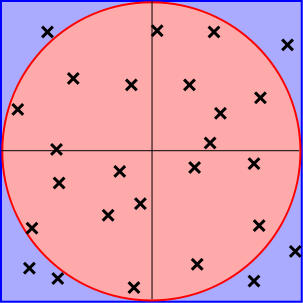

Punti casuali nel quadrato e nel cerchio inscritto (dispensa originale).

### Esercizio 9 (facoltativo)

Scrivete `montecarlo(n)` per approssimare π con questo procedimento. Potete generare tutti i punti con `2 .* rand(n, 2) .- 1`. I confronti elemento per elemento si scrivono `.<=`; `count` conta i valori veri in un array booleano.

Per ripetere un esperimento potete fissare il generatore con `Random.seed!(1234)` prima delle prove, senza reinizializzarlo dentro ogni chiamata.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 9

### Esercizio 10 (facoltativo)

Quanto rapidamente converge? Calcolate il risultato per $n=2^k$ fino a circa $50000$ e tracciate $k$ contro $\log|\operatorname{montecarlo}(2^k)-\pi|$. Provate anche `plot(ns, errori; yscale=:log10)` (analogo di `semilogy`) e la scala log-log.

Ripetete le prove: l’errore è casuale e non deve diminuire monotonamente. Evitate di passare errori esattamente nulli a un asse logaritmico.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 10

### Esercizio 11 (facoltativo)

Stimate l’ordine di convergenza dai risultati. Per una stima più affidabile confrontate la media degli errori quadratici su più prove indipendenti, invece di una sola traiettoria casuale.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 11

### Esercizio 12 (facoltativo)

Contate invece i punti con $x^2+y^2\leq1/2$. A quale numero converge la quantità $4r/n$? Come va riscalata per stimare ancora $\pi$? Converge più o meno velocemente? Distinguete l’ordine di convergenza dalla costante dell’errore. Provate a spiegarlo con il teorema del limite centrale.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 12

### Esercizio 13 (facoltativo)

Approssimate allo stesso modo $\int_0^1 x^2\,dx$: quanti punti uniformi in $[0,1]^2$ cadono sotto la parabola? Confrontate con il valore esatto.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 13

Riferimento per gli adattamenti: [AbstractFFTs.jl: definizioni di FFT e IFFT](https://juliamath.github.io/AbstractFFTs.jl/stable/api/).